In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base = '/content/drive/MyDrive/EdgeTB_Project'
folders = [
    f'{base}/datasets/train/TB',
    f'{base}/datasets/train/Normal',
    f'{base}/datasets/val/TB',
    f'{base}/datasets/val/Normal',
    f'{base}/datasets/test/TB',
    f'{base}/datasets/test/Normal',
    f'{base}/datasets/shenzhen',
    f'{base}/models',
    f'{base}/results'
]
for folder in folders:
    os.makedirs(folder, exist_ok=True)
    print(f'Created: {folder}')

Created: /content/drive/MyDrive/EdgeTB_Project/datasets/train/TB
Created: /content/drive/MyDrive/EdgeTB_Project/datasets/train/Normal
Created: /content/drive/MyDrive/EdgeTB_Project/datasets/val/TB
Created: /content/drive/MyDrive/EdgeTB_Project/datasets/val/Normal
Created: /content/drive/MyDrive/EdgeTB_Project/datasets/test/TB
Created: /content/drive/MyDrive/EdgeTB_Project/datasets/test/Normal
Created: /content/drive/MyDrive/EdgeTB_Project/datasets/shenzhen
Created: /content/drive/MyDrive/EdgeTB_Project/models
Created: /content/drive/MyDrive/EdgeTB_Project/results


In [ ]:
import os

# Create the results folders
os.makedirs('/content/drive/MyDrive/EdgeTB_Project/results/evaluation', exist_ok=True)
os.makedirs('/content/drive/MyDrive/EdgeTB_Project/results/training_curves', exist_ok=True)
print("Folders created")

Folders created


In [ ]:
pip install tensorflow opencv-python scikit-learn matplotlib seaborn

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Paths to your data
TRAIN_DIR = '/content/drive/MyDrive/EdgeTB_Project/datasets/train'
VAL_DIR   = '/content/drive/MyDrive/EdgeTB_Project/datasets/val'

# Data augmentation for training
train_gen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.1,
    brightness_range=[0.8, 1.2]
)
val_gen = ImageDataGenerator(rescale=1./255)

train_data = train_gen.flow_from_directory(
    TRAIN_DIR, target_size=(224,224),
    batch_size=32, class_mode='binary'
)
val_data = val_gen.flow_from_directory(
    VAL_DIR, target_size=(224,224),
    batch_size=32, class_mode='binary'
)

# Build MobileNetV2
base = MobileNetV2(input_shape=(224,224,3),
                   include_top=False, weights='imagenet')
base.trainable = False

model = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Train
history = model.fit(
    train_data, validation_data=val_data,
    epochs=20,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=5, restore_best_weights=True)]
)

# Save model
model.save('/content/drive/MyDrive/EdgeTB_Project/models/mobilenetv2_tb.h5')
print("Model saved.")

Found 2940 images belonging to 2 classes.
Found 630 images belonging to 2 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1665s 18s/step - accuracy: 0.9112 - loss: 0.2449 - val_accuracy: 0.9540 - val_loss: 0.1014
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 75s 820ms/step - accuracy: 0.9684 - loss: 0.0996 - val_accuracy: 0.9651 - val_loss: 0.0799
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 77s 836ms/step - accuracy: 0.9741 - loss: 0.0725 - val_accuracy: 0.9714 - val_loss: 0.0685
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 77s 836ms/step - accuracy: 0.9789 - loss: 0.0651 - val_accuracy: 0.9730 - val_loss: 0.0661
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 76s 828ms/step - accuracy: 0.9823 - loss: 0.0567 - val_accuracy: 0.9746 - val_loss: 0.0611
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 75s 817ms/step - accuracy: 0.9837 - loss: 0.0512 - val_accuracy: 0.9714 - val_loss: 0.0668
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 77s 840ms/step - accuracy: 0.9830 - loss: 0.0509 - val_a

Model saved.


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Paths to your data
TRAIN_DIR = '/content/drive/MyDrive/EdgeTB_Project/datasets/train'
VAL_DIR   = '/content/drive/MyDrive/EdgeTB_Project/datasets/val'

# Data augmentation for training
train_gen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.1,
    brightness_range=[0.8, 1.2]
)
val_gen = ImageDataGenerator(rescale=1./255)

train_data = train_gen.flow_from_directory(
    TRAIN_DIR, target_size=(224,224),
    batch_size=32, class_mode='binary'
)
val_data = val_gen.flow_from_directory(
    VAL_DIR, target_size=(224,224),
    batch_size=32, class_mode='binary'
)

# Build VGG16
base = VGG16(input_shape=(224,224,3),
                   include_top=False, weights='imagenet')
base.trainable = False

model = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Train
history = model.fit(
    train_data, validation_data=val_data,
    epochs=20,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=5, restore_best_weights=True)]
)

# Save model
model.save('/content/drive/MyDrive/EdgeTB_Project/models/VGG16_tb.h5')
print("Model saved.")

Found 2940 images belonging to 2 classes.
Found 630 images belonging to 2 classes.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.8088 - loss: 0.4750 - val_accuracy: 0.8333 - val_loss: 0.4138
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 80s 865ms/step - accuracy: 0.8330 - loss: 0.4121 - val_accuracy: 0.8333 - val_loss: 0.3703
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 82s 896ms/step - accuracy: 0.8371 - loss: 0.3680 - val_accuracy: 0.8349 - val_loss: 0.3349
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 81s 881ms/step - accuracy: 0.8483 - loss: 0.3394 - val_accuracy: 0.8429 - val_loss: 0.3075
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 80s 873ms/step - accuracy: 0.8656 - loss: 0.3166 - val_accuracy: 0.8762 - val_loss: 0.2849
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 81s 872ms/step - accuracy: 0.8711 - loss: 0.2966 - val_accuracy: 0.8841 - val_loss: 0.2658
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 81s 879ms/step - accuracy: 0.8878 - loss: 0.2764 - val_a

Model saved.


In [ ]:
import os, shutil, random

TB_TRAIN     = '/content/drive/MyDrive/EdgeTB_Project/datasets/train/TB'
NORMAL_TRAIN = '/content/drive/MyDrive/EdgeTB_Project/datasets/train/Normal'
TB_VAL       = '/content/drive/MyDrive/EdgeTB_Project/datasets/val/TB'
NORMAL_VAL   = '/content/drive/MyDrive/EdgeTB_Project/datasets/val/Normal'
TB_TEST      = '/content/drive/MyDrive/EdgeTB_Project/datasets/test/TB'
NORMAL_TEST  = '/content/drive/MyDrive/EdgeTB_Project/datasets/test/Normal'

# Create folders if they do not exist
for folder in [TB_VAL, NORMAL_VAL, TB_TEST, NORMAL_TEST]:
    os.makedirs(folder, exist_ok=True)

def split_class(train_path, val_path, test_path, val_pct=0.15, test_pct=0.15):
    images = [f for f in os.listdir(train_path)
              if f.endswith(('.jpg', '.jpeg', '.png'))]
    random.shuffle(images)

    val_count  = int(len(images) * val_pct)
    test_count = int(len(images) * test_pct)

    val_images  = images[:val_count]
    test_images = images[val_count:val_count + test_count]

    for img in val_images:
        shutil.move(os.path.join(train_path, img),
                    os.path.join(val_path, img))
    for img in test_images:
        shutil.move(os.path.join(train_path, img),
                    os.path.join(test_path, img))

    remaining = len([f for f in os.listdir(train_path)
                     if f.endswith(('.jpg','.jpeg','.png'))])
    print(f"Train: {remaining} | Val: {val_count} | Test: {test_count}")

print("TB split:")
split_class(TB_TRAIN, TB_VAL, TB_TEST)

print("Normal split:")
split_class(NORMAL_TRAIN, NORMAL_VAL, NORMAL_TEST)

TB split:
Train: 490 | Val: 105 | Test: 105
Normal split:
Train: 2450 | Val: 525 | Test: 525


Found 630 images belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 99s 4s/step

--- MobileNetV2 ---
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       525
          TB       1.00      0.98      0.99       105

    accuracy                           1.00       630
   macro avg       1.00      0.99      0.99       630
weighted avg       1.00      1.00      1.00       630

AUC-ROC: 1.0000
Sensitivity: 0.9810
Specificity: 1.0000
TB cases missed: 2 out of 105


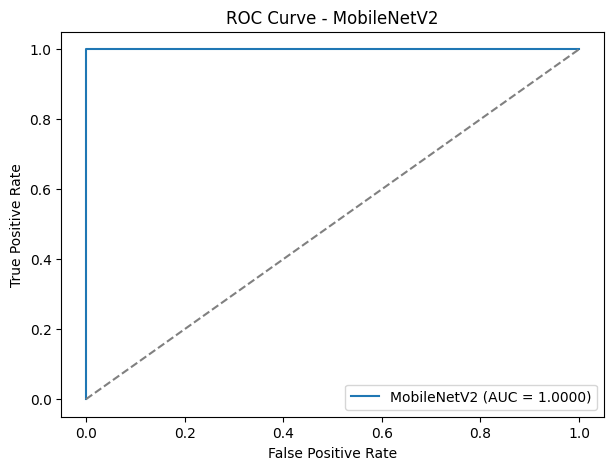

Found 630 images belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 981ms/step

--- VGG16 ---
              precision    recall  f1-score   support

      Normal       0.93      1.00      0.96       525
          TB       0.99      0.64      0.77       105

    accuracy                           0.94       630
   macro avg       0.96      0.82      0.87       630
weighted avg       0.94      0.94      0.93       630

AUC-ROC: 0.9827
Sensitivity: 0.6381
Specificity: 0.9981
TB cases missed: 38 out of 105


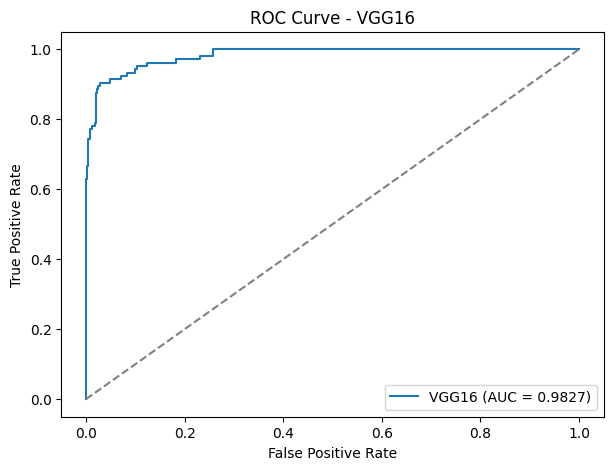


Comparison:
Metric           MobileNetV2        VGG16
AUC-ROC                  1.0       0.9827
Sensitivity            0.981       0.6381
Specificity              1.0       0.9981


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def evaluate_model(model_path, model_name):

    model = load_model(model_path)

    # load test images, just rescale them
    gen = ImageDataGenerator(rescale=1./255)
    test_data = gen.flow_from_directory(
        '/content/drive/MyDrive/EdgeTB_Project/datasets/test',
        target_size=(224, 224),
        batch_size=32,
        class_mode='binary',
        shuffle=False
    )

    # run predictions
    probs  = model.predict(test_data)
    preds  = (probs > 0.5).astype(int).flatten()
    actual = test_data.classes

    print(f"\n--- {model_name} ---")
    print(classification_report(actual, preds, target_names=['Normal', 'TB']))

    # auc
    auc = roc_auc_score(actual, probs)
    print(f"AUC-ROC: {auc:.4f}")

    # sensitivity and specificity from confusion matrix
    cm = confusion_matrix(actual, preds)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    print(f"Sensitivity: {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"TB cases missed: {fn} out of {tp + fn}")

    # roc curve
    fpr, tpr, _ = roc_curve(actual, probs)
    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], 'grey', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend()
    plt.savefig(
        f'/content/drive/MyDrive/EdgeTB_Project/results/evaluation/roc_{model_name.lower().replace(" ", "_")}.png'
    )
    plt.show()

    return {'model': model_name, 'auc': round(auc, 4),
            'sensitivity': round(sensitivity, 4), 'specificity': round(specificity, 4)}


# run evaluation for both models
r1 = evaluate_model(
    '/content/drive/MyDrive/EdgeTB_Project/models/mobilenetv2_tb.h5', 'MobileNetV2'
)
r2 = evaluate_model(
    '/content/drive/MyDrive/EdgeTB_Project/models/VGG16_tb.h5', 'VGG16'
)

# print a simple comparison
print("\nComparison:")
print(f"{'Metric':<15} {'MobileNetV2':>12} {'VGG16':>12}")
print(f"{'AUC-ROC':<15} {r1['auc']:>12} {r2['auc']:>12}")
print(f"{'Sensitivity':<15} {r1['sensitivity']:>12} {r2['sensitivity']:>12}")
print(f"{'Specificity':<15} {r1['specificity']:>12} {r2['specificity']:>12}")

In [ ]:
# save results to Drive
results_text = f"""Model Comparison - Internal Test Set (Kaggle TB Chest X-Ray Database)

MobileNetV2
  AUC-ROC:     {r1['auc']}
  Sensitivity: {r1['sensitivity']}
  Specificity: {r1['specificity']}

VGG16
  AUC-ROC:     {r2['auc']}
  Sensitivity: {r2['sensitivity']}
  Specificity: {r2['specificity']}

Decision: MobileNetV2 selected for deployment.
Reason: Higher sensitivity ({r1['sensitivity']} vs {r2['sensitivity']}).
        In TB screening, missing a positive case is more dangerous
        than a false alarm, so sensitivity is the priority metric.
"""

with open('/content/drive/MyDrive/EdgeTB_Project/results/evaluation/model_comparison.txt', 'w') as f:
    f.write(results_text)

print("Results saved")

Results saved
